# Stimulus-programme rollout tool

Notebook full run generates:

- simulated fish trajectories
- mp4 file of selected sequences

**Inputs :**

 - stimulus trajectory file : `assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz` 
 - trained model : `assets/models/ladder_b_indiv.pt` 

Choosing rollout parameters : 

 - MODEL_KEY : J10 is current best model, it is the only one in the current keys available for the repo.
 - N_ROLLOUTS : number of rollouts to generate, 3 as a minimum is recommended to be able to generate the mp4 file correctly (video shows first 3 rollouts)
 - WINDOWS : set `WINDOWS = [(lo, hi, 'label'), (lo2, hi2, 'label2')]` in frames.
 - VIDEO_SPEED : speed of mp4 video render, 3.0 is default.

In [1]:
import sys, time, json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'scripts').exists() and (ROOT.parent / 'scripts').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if not hasattr(np, '_core'):                 # load Colab (numpy 2) checkpoints under numpy 1
    import numpy.core as _nc; np._core = _nc

def pick(*candidates):
    """First path that exists, else None. Everything the tool reads is resolved this way:
    the full local dataset when you have it, the small shipped assets/ copy otherwise."""
    for c in candidates:
        p = ROOT / c
        if p.exists():
            return p
    return None

TRAJ_FILE = pick('assets/stimulus/2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz')
ROI_FILE  = pick('assets/ROIdef2025-02-20T12_09_16.csv')
BOUTS     = None      # None in a clean clone
REFERENCE = pick('assets/real_reference.npz')

# Params
MODEL_KEY  = 'J10'          
N_ROLLOUTS = 3              
SEED       = 0
WINDOWS    = None           # None = auto-pick two contrasting blocks
VIDEO_SPEED = 3.0           # 3x real time
OUT_DIR    = ROOT / 'tool_videos'

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'figure.dpi': 110})
REAL, GEN = '#3C3C3C', '#1F3B8C'
print('ROOT     ', ROOT)
print('python   ', sys.version.split()[0], '| numpy', np.__version__)
print('stimulus ', TRAJ_FILE.name if TRAJ_FILE else 'MISSING')
print('roi      ', ROI_FILE.name if ROI_FILE else 'MISSING')
print('reference', 'bouts CSV (full local data)' if BOUTS else
                   (REFERENCE.name if REFERENCE else 'MISSING'))
assert TRAJ_FILE and ROI_FILE and (BOUTS or REFERENCE), 'missing inputs -- see the README'

ROOT      C:\Users\arthu\mp_semiCL_behavior
python    3.14.6 | numpy 2.4.3
stimulus  2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz
roi       ROIdef2025-02-20T12_09_16.csv
reference real_reference.npz


In [2]:
import evaluate as E, fit_MLP_border as MB, fit_MLP_mix as MX
import stim_program as SP, stim_rollout as SR, tool_video as TV, tool_reference as TR

# key -> candidate paths, first existing wins. Only J10 ships with the repo
MODELS = {
    'J10':           ['assets/models/ladder_b_indiv.pt',        # the thesis J10 (traj AUC 0.704)
                      'notebooks/_zip_full/ladder_b_indiv.pt'],
    'J10_150ep':     ['ladder_b_indiv150.pt'],                  # same recipe, 150 epochs
    'J10_cal2q':     ['ladder_b_indiv150_cal2q.pt'],            # recalibrated containment
    'J10_psi_basis': ['ladder_b_indiv_psib_cal2q.pt'],          # J10 + psi-frame + border basis
    'J17':           ['ladder_re_swap_gr.pt'],                  # fitted per-fish latent, m=2
}
_p = pick(*MODELS[MODEL_KEY])
if _p is None:
    raise FileNotFoundError(
        f"{MODEL_KEY} not found. Tried: {MODELS[MODEL_KEY]}. "
        f"Only 'J10' ships with the repo; the others need the full research checkout.")
model = MX.load_mix(str(_p))
cf = model._cfg_feat

records = MB.build_border_records(E.load_bouts(str(BOUTS)), roi_path=str(ROI_FILE)) if BOUTS else None
ref = TR.reference_from_records(records) if records else TR.load_reference(REFERENCE)

In [3]:
# Load stim program file
program = SP.load_program(TRAJ_FILE)
print(program.summary())


program.block_table().head(10)

2025.02.20-0957_trajectory_GsizeMotionSingle_180min.csv.gz: 315000 frames (175.0 min @ 30 fps), 8 dot slots
  191 blocks -> 95 stimulus / 96 pause
  16 conditions; N in [1, 2, 4, 6, 8]; moving 60 / static 35


,block,label,start_frame,end_frame,dur_s,n_dots,moving,side,is_stim
0,0,none,0,1500,50.0,0.0,False,none,False
1,1,CLsemi1800_g4-0_s3.5-3.5,1500,3300,60.0,4.0,True,left,True
2,2,none,3300,4800,50.0,0.0,False,none,False
3,3,CLsemi1800_g0-2_s3.5-3.5,4800,6600,60.0,2.0,True,right,True
4,4,none,6600,8100,50.0,0.0,False,none,False
5,5,CLsemi1800_g0-4_s3.5-3.5,8100,9900,60.0,4.0,True,right,True
6,6,none,9900,11400,50.0,0.0,False,none,False
7,7,CLsemi1800_g8-0_s3.5-3.5,11400,13200,60.0,8.0,True,left,True
8,8,none,13200,14700,50.0,0.0,False,none,False
9,9,CLsemi1800_g0-4_s0-0,14700,16500,60.0,4.0,False,right,True


In [4]:
# NGenerate rollouts
dish = SR.default_dish(roi_path=str(ROI_FILE))

t0 = time.time()
rollouts = SR.rollout_many(model, program, N_ROLLOUTS, seed=SEED,
                           dish=dish, pose_sampler=ref.sample_start_pose)
print(f'{N_ROLLOUTS} rollouts in {time.time() - t0:.1f}s')

  rollout 0: 4717 bouts, last onset 174.99 of 175.00 min (short by 0.5s), median dt 1.51s, max r/R 0.999, 2.1s


  rollout 1: 5419 bouts, last onset 174.88 of 175.00 min (short by 7.5s), median dt 1.33s, max r/R 0.999, 2.4s


  rollout 2: 5207 bouts, last onset 174.91 of 175.00 min (short by 5.3s), median dt 1.37s, max r/R 0.993, 4.1s
3 rollouts in 8.5s


## Warning : model is bout-indexed, not time-indexed

The stimulus programme is read **once per bout onset**, this means:

1. The fish is blind between bouts 
2. A stimulus block change is noticed at the first bout after the onset frame, not at the frame itself.
3. The run ends at the last bout whose onset is still inside the programme, meaning the trajectory *undershoots* the programme by one inter-bout interval.

In [5]:
rows = []
for k, g in enumerate(rollouts):
    cx, cy, R = g['dish']
    rr = np.hypot(g['x_px'] - cx, g['y_px'] - cy) / R
    rows.append(dict(rollout=k, bouts=len(g['dtheta']),
                     last_onset_min=g['last_onset_s'] / 60,
                     short_by_s=g['program_s'] - g['last_onset_s'],
                     final_dt_s=float(g['dt_s'][-1]),
                     median_dt_s=float(np.median(g['dt_s'])),
                     mean_rR=float(rr.mean()), max_rR=float(rr.max()),
                     outside_dish=int((rr > 1.0).sum()), wall_s=g['wall_s']))
clock = pd.DataFrame(rows)
clock.round(3)

,rollout,bouts,last_onset_min,short_by_s,final_dt_s,median_dt_s,mean_rR,max_rR,outside_dish,wall_s
0,0,4717,174.991,0.520,0.919,1.512,0.434,0.999,0,2.069
1,1,5419,174.876,7.470,12.032,1.331,0.404,0.999,0,2.373
2,2,5207,174.911,5.329,11.725,1.367,0.307,0.993,0,4.094


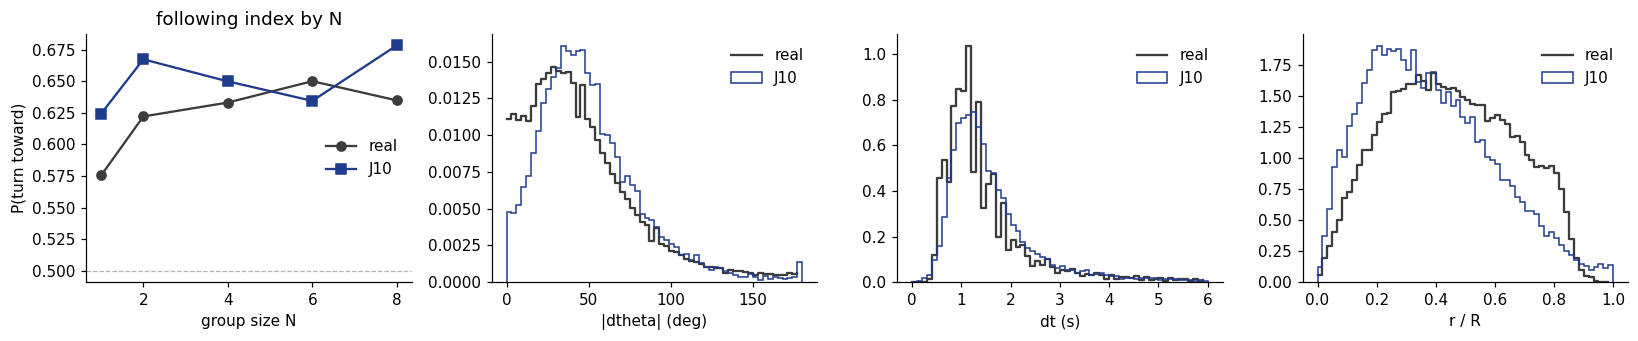

following index  real: {1: 0.576, 2: 0.622, 4: 0.633, 6: 0.65, 8: 0.635}
                 gen : {1: 0.624, 2: 0.667, 4: 0.65, 6: 0.634, 8: 0.678}
mean r/R  real 0.449  gen 0.381   | frames outside dish: 0


In [6]:
# Comparison plots (Following index, theta distribution, dt distribution, radial occupancy distribution)

c = ref.curves

gen_d  = np.concatenate([g['dtheta'] for g in rollouts])
gen_p  = np.concatenate([g['stim_angle_gen'] for g in rollouts])
gen_dt = np.concatenate([g['dt_s'] for g in rollouts])
gen_rr = np.concatenate([np.hypot(g['x_px'] - g['dish'][0], g['y_px'] - g['dish'][1]) / g['dish'][2]
                         for g in rollouts])
gen_n  = np.concatenate([program.n_dots_of[g['block_id']] for g in rollouts])
gen_mv = np.concatenate([program.moving_of[g['block_id']].astype(float) for g in rollouts])

fi_real = c['following_by_n']
fi_gen  = TR.following_by_n(gen_d, gen_p, gen_n, gen_mv)      # same function both sides

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
ax[0].plot(list(fi_real), list(fi_real.values()), 'o-', color=REAL, label='real')
ax[0].plot(list(fi_gen), list(fi_gen.values()), 's-', color=GEN, label=MODEL_KEY)
ax[0].axhline(0.5, color='0.7', lw=0.8, ls='--')
ax[0].set(xlabel='group size N', ylabel='P(turn toward)', title='following index by N')
ax[0].legend(frameon=False)
for a, (key, gv, lab) in zip(ax[1:], [('abs_dtheta', np.abs(gen_d), '|dtheta| (deg)'),
                                      ('dt', gen_dt, 'dt (s)'),
                                      ('rr', gen_rr, 'r / R')]):
    dens, edges = c[key]
    a.step(edges[:-1], dens, where='post', color=REAL, label='real')
    a.hist(gv[np.isfinite(gv)], bins=len(dens), range=(edges[0], edges[-1]),
           density=True, histtype='step', color=GEN, label=MODEL_KEY)
    a.set(xlabel=lab); a.legend(frameon=False)
plt.tight_layout(); plt.show()

print('following index  real:', {k: round(v, 3) for k, v in fi_real.items()})
print('                 gen :', {k: round(v, 3) for k, v in fi_gen.items()})
print(f"mean r/R  real {c['mean_rR']:.3f}  gen {gen_rr.mean():.3f}   "
      f'| frames outside dish: {int((gen_rr > 1.0).sum())}')

## Note : Video generation takes time...

Give it approx 4 min to generate the mp4 files and save them. 


In [7]:
# Choose video windows
# Default: the first MOVING block at the largest group size, and the first STATIC block at the
windows = WINDOWS if WINDOWS is not None else TV.pick_windows(program)
for i, (lo, hi, lab) in enumerate(windows):
    print(f'row {i}: {lab}  frames {lo}-{hi}  ({(hi - lo) / program.fps:.0f}s)')

row 0: CLsemi1800_g8-0_s3.5-3.5  frames 11400-13200  (60s)
row 1: CLsemi1800_g8-0_s0-0  frames 18000-19800  (60s)


In [8]:
# Save mp4
OUT_DIR.mkdir(parents=True, exist_ok=True)
stem = TRAJ_FILE.name.removesuffix('.gz').removesuffix('.csv')
out_mp4 = OUT_DIR / f'{stem}__{MODEL_KEY}.mp4'

t0 = time.time()
out_mp4, manifest = TV.make_tool_video(rollouts, program, out_mp4,
                                       windows=windows, n_cols=3, speed=VIDEO_SPEED)
print(f'\nrendered in {time.time() - t0:.0f}s -> {out_mp4}')
print(f'{manifest["n_frames"]} frames/panel at {manifest["fps"]} fps x {VIDEO_SPEED} speed')

  row 0: CLsemi1800_g8-0_s3.5-3.5
[frames 11400-13200]
  row 1: CLsemi1800_g8-0_s0-0
[frames 18000-19800]
  1800 frames/panel -> C:\Users\arthu\mp_semiCL_behavior\tool_videos\2025.02.20-0957_trajectory_GsizeMotionSingle_180min__J10.mp4



rendered in 230s -> C:\Users\arthu\mp_semiCL_behavior\tool_videos\2025.02.20-0957_trajectory_GsizeMotionSingle_180min__J10.mp4
1800 frames/panel at 30 fps x 3.0 speed
